# MAST30034 Project 2 — Sprint 6 Final Results

This notebook integrates the saved Sprint 1–5 evidence into a concise final-results walkthrough. **The overall project objective is a five-year rental-growth scenario (2025 Q3–2030 Q3); Sprint 6 additionally requires an explicit three-year prediction output (2025 Q3–2028 Q3).** Both forecast tables and Top-10 rankings are preserved.

All calculations in this notebook are offline summaries, integrity checks, or visualizations of saved local outputs. It does not call an API or ORS, download data, or modify Notebooks 00–05. Run from the repository root.

## 1. Project question and evidence path

We examine what is associated with current asking rent, how historical rental-market trajectories project forward, and which SA2 areas pass a preliminary affordability/liveability screen. The overall project objective is five-year rental-growth analysis; the Sprint 6 checkpoint also requires a complete three-year forecast output. The feature-analysis unit is an SA2 aggregate; the forecast unit is a distinct Homes Victoria rental-history trajectory.

Loaded the curated Sprint 6 presentation cache and saved offline diagnostics; no upstream data rebuild or API calls.


,Data layer,Existing source,Role and boundary
0,Listings,Domain + Kaggle Victoria snapshots,"Listing-level asking rent, attributes and coor..."
1,Recent rent history,"Homes Victoria SA2 panel, 2023 Q1–2025 Q3",277 SA2s; supports current/short-medium contex...
2,Long rent history,"Homes Victoria moving annual median, 2000-03-3...",All-properties rent target; distinct rental-hi...
3,Geography,ABS ASGS 2021 SA2,Common area key for spatial analysis; SA2 is n...
4,Area context,2021 Census/SEIFA and VIF projections,"Household income, IRSAD and projected populati..."
5,Transport and amenities,"Saved routes, public transport, schools and st...","13,831 valid route origins and 35,104 statewid..."


,feature_family,q1_current_rent_analysis,q2_growth_analysis,q3_affordability_liveability
0,Property characteristics,"Predictors: median bathrooms, parking and prop...",Not used in the selected time-series path mode...,Not part of the affordability ratio or the pro...
1,Socioeconomic context,Predictors: IRSAD and household income are pro...,Not used in the selected time-series path mode...,Median household weekly income is the denomina...
2,Transport accessibility,Train driving time appears among the saved per...,No transport accessibility feature is used by ...,Nearest-train and nearest-school straight-line...
3,Local amenities,Nearest shopping distance and park count withi...,"No park, shopping or entertainment feature is ...","Park, shopping and entertainment POI counts wi..."
4,Rent level and history,Current SA2 median asking rent is the predicti...,The path models forecast historical rent traje...,Current median weekly rent is the numerator in...


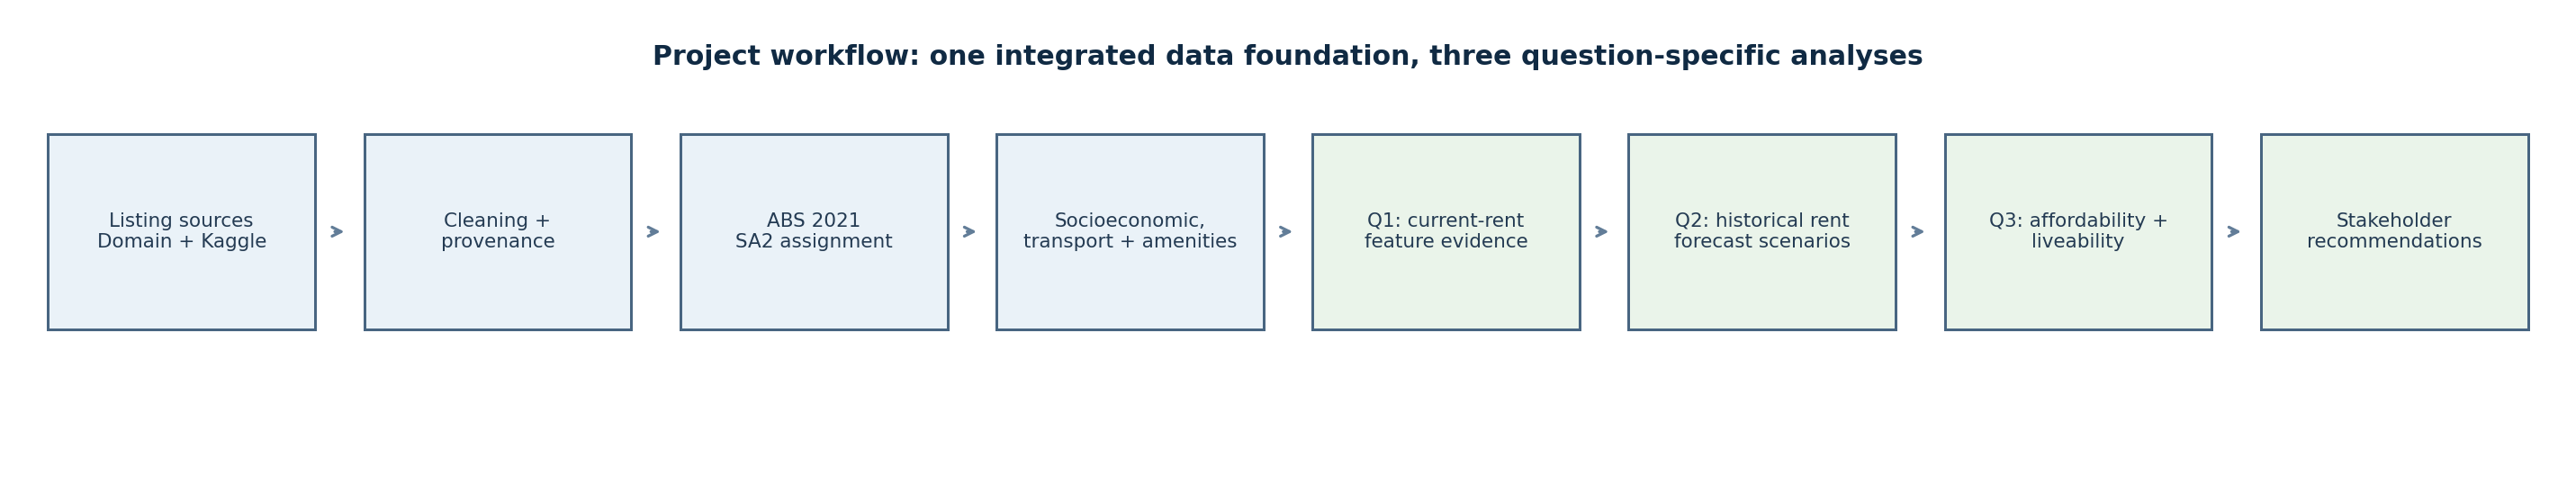

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd()
if not (ROOT / 'src' / 'sprint6_summary.py').is_file():
    ROOT = ROOT.parent
if not (ROOT / 'src' / 'sprint6_summary.py').is_file():
    raise RuntimeError('Run this notebook from the project repository or its notebooks folder.')
sys.path.insert(0, str(ROOT))
from src.sprint6_summary import INPUTS, build_sprint6_outputs
from src.sprint6_notebook_cache import cache_is_complete, load_cached_notebook_result, write_notebook_cache
from src.sprint6_methodological_validation import run_all_validations
if cache_is_complete(ROOT):
    result = load_cached_notebook_result(ROOT)
    print('Loaded the curated Sprint 6 presentation cache and saved offline diagnostics; no upstream data rebuild or API calls.')
else:
    missing_inputs = [relative_path for relative_path in INPUTS.values() if not (ROOT / relative_path).is_file()]
    if missing_inputs:
        raise FileNotFoundError('Sprint 6 cache is incomplete and saved local prerequisites are missing: ' + ', '.join(missing_inputs))
    print(f'Verified {len(INPUTS)} saved Sprint 1–5 inputs; rebuilding only offline Sprint 6 summaries and diagnostics.')
    result = build_sprint6_outputs(ROOT)
    write_notebook_cache(ROOT, result)
    run_all_validations(ROOT)
    result = load_cached_notebook_result(ROOT)
    if not cache_is_complete(ROOT):
        raise RuntimeError('The offline Sprint 6 presentation cache or its diagnostics were not completed.')
display(result['data_overview'])
display(result['feature_crosswalk'][['feature_family','q1_current_rent_analysis','q2_growth_analysis','q3_affordability_liveability']])
display(Image(filename=str(result['figure_paths']['workflow'])))

## 2. Data sources and project workflow

The 13,835 integrated listing observations come from the teacher-provided Domain snapshot and the public Kaggle snapshot; the project does not establish that these records were live-scraped by the group. Notebook 1 contains a parser/crawler implementation, but its authorised URL list is empty and its local HTML fixture is synthetic. The long Homes Victoria archive is a moving annual median series, while the recent SA2 panel is a shorter quarter-specific source view. The saved source-vintage reconciliation found all 2024 Q1–2025 Q3 overlap values equal; 235 of 1,108 values differed in 2023 (maximum absolute difference AUD 121/week), consistent with the documented source-vintage distinction. The experimental mapped long-history panel is not substituted into the existing forecasts.

## 3. Q1 — Predictors of current asking rent

The saved comparison uses one Random Forest holdout with 98 SA2 rows. Lower RMSE/MAE indicates lower prediction error on this holdout; R² summarizes target variation explained on that split. The additional five-fold check below is a robustness analysis over 487 unique SA2 rows, not geographic-transfer validation. Both analyses show predictive association, not causation. Permutation importance measures how much holdout error increases when a feature is shuffled; it does not show the direction of the relationship.

,feature_set,feature_set_label,model,test_rows,mae_aud_week,rmse_aud_week,r2
0,internal_socioeconomic_transport_amenities,Property + socioeconomic + transport + amenities,random_forest,98,70.750,114.639,0.510
1,internal_socioeconomic,Property + socioeconomic,random_forest,98,73.209,117.651,0.484
2,internal_socioeconomic_transport,Property + socioeconomic + transport,random_forest,98,70.167,118.637,0.476
3,internal_property,Property only,random_forest,98,84.068,131.820,0.353


,feature,feature_category,mae_increase_when_shuffled,shuffle_std,direction_relationship
0,irsad_score,Socioeconomic context,48.26,4.91,Positive monotonic association in the SA2 feat...
1,median_bathrooms,Internal property characteristics,4.69,1.16,Positive monotonic association in the SA2 feat...
2,nearest_shopping_distance_km,Amenities,2.71,0.76,Negative monotonic association in the SA2 feat...
3,median_household_income,Socioeconomic context,2.32,0.89,Positive monotonic association in the SA2 feat...
4,median_parking_spaces,Internal property characteristics,1.52,0.40,Weak or unclear monotonic association
5,park_named_within_2km,Amenities,1.46,0.46,Positive monotonic association in the SA2 feat...
6,population_growth_pct,Socioeconomic context,1.10,1.35,Positive monotonic association in the SA2 feat...
7,property_type_share_apartment,Internal property characteristics,1.05,0.60,Positive monotonic association in the SA2 feat...


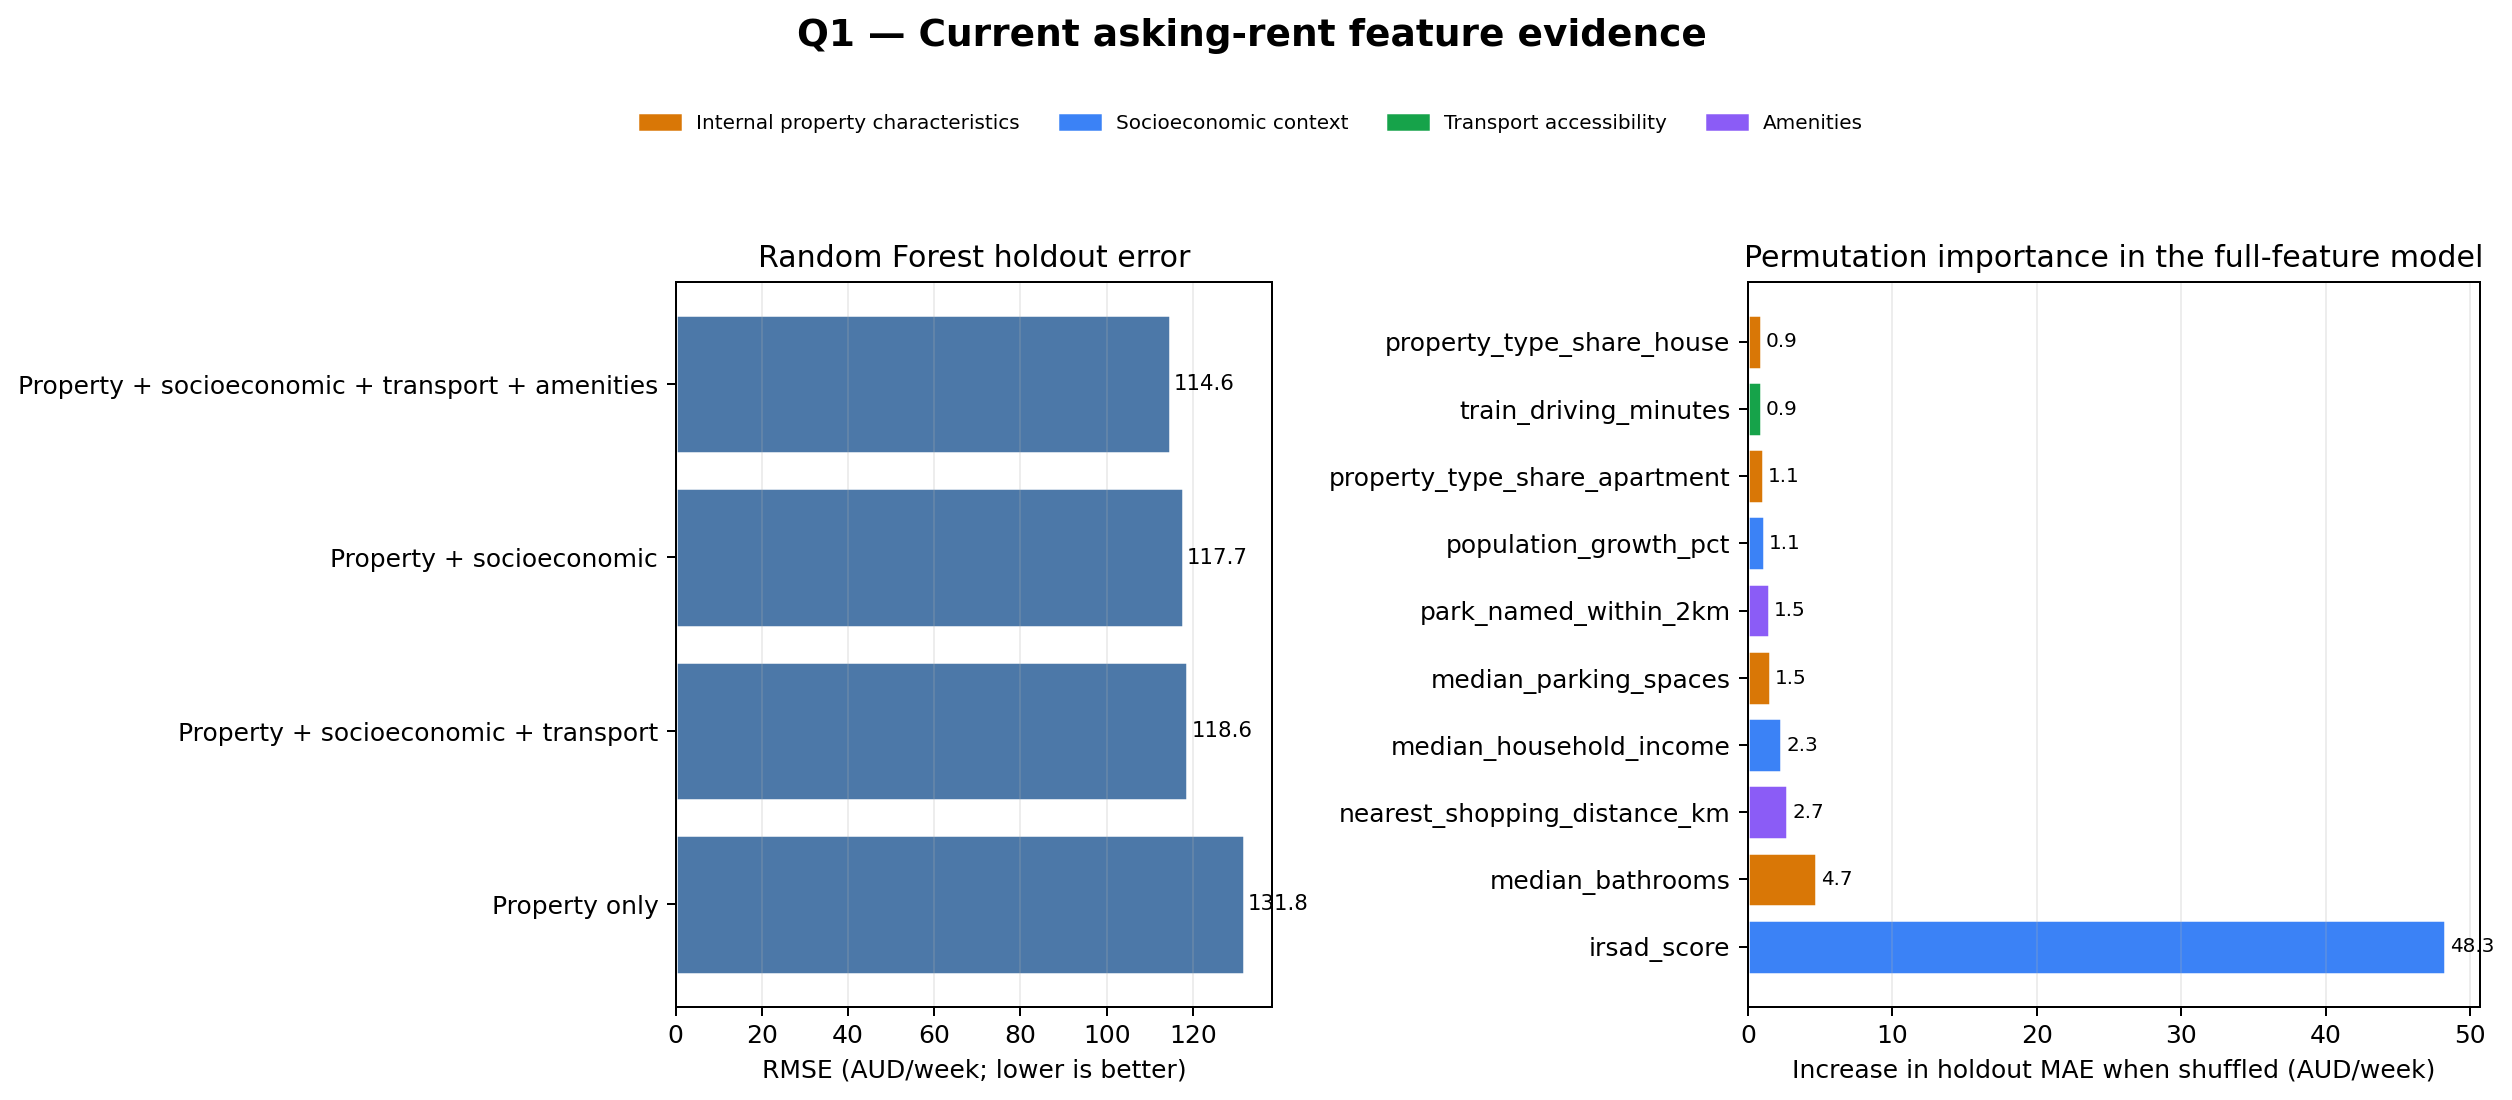

**Answer to Q1.** On the saved Random Forest holdout, the full property, socioeconomic, transport and amenity feature set produced an RMSE of AUD 114.64 per week, compared with AUD 131.82 for property characteristics alone and AUD 117.65 for the socioeconomic-only set. The comparison covers 98 held-out SA2 feature rows, not 98 individual listings. IRSAD had the largest saved permutation-importance value: shuffling it increased holdout MAE by about AUD 48.26 per week (±4.91). This indicates model reliance in this split; it does not show that IRSAD causes rent differences or indicate a causal effect. Adding transport alone to the socioeconomic set slightly increased RMSE, while the complete set had the lowest error. Overall, the wider context provides useful predictive information in this saved comparison, but one holdout is limited evidence—not proof of universal importance.

**Five-fold robustness check** (same five folds for all models; preprocessing fitted inside each training fold):

,feature_set,model,mean_mae_aud_week,sd_mae_aud_week,mean_rmse_aud_week,sd_rmse_aud_week,mean_r2,sd_r2,folds,observations_evaluated
0,internal_property,random_forest,80.308,5.371,113.684,11.109,0.277,0.111,5,487
1,internal_property,ridge,88.973,8.918,133.117,17.292,0.003,0.234,5,487
2,internal_socioeconomic,random_forest,61.438,2.045,88.046,9.854,0.567,0.065,5,487
3,internal_socioeconomic,ridge,70.361,3.693,103.473,12.802,0.398,0.135,5,487
4,internal_socioeconomic_transport,random_forest,59.333,1.567,86.663,10.270,0.581,0.067,5,487
5,internal_socioeconomic_transport,ridge,69.617,4.137,103.147,12.738,0.402,0.130,5,487
6,internal_socioeconomic_transport_amenities,random_forest,59.350,2.547,85.522,7.499,0.592,0.041,5,487
7,internal_socioeconomic_transport_amenities,ridge,68.563,2.252,100.973,10.534,0.431,0.079,5,487


In [2]:
display(result['q1_summary'].round(3))
display(result['q1_feature_importance'][['feature','feature_category','mae_increase_when_shuffled','shuffle_std','direction_relationship']].head(8).round(2))
display(Image(filename=str(result['figure_paths']['q1'])))
display(Markdown('**Answer to Q1.** ' + result['q1_answer']))
q1_cv = pd.read_csv(ROOT / 'data/processed/sprint6/q1_cross_validation/q1_cv_summary.csv')
display(Markdown('**Five-fold robustness check** (same five folds for all models; preprocessing fitted inside each training fold):'))
display(q1_cv[['feature_set','model','mean_mae_aud_week','sd_mae_aud_week','mean_rmse_aud_week','sd_rmse_aud_week','mean_r2','sd_r2','folds','observations_evaluated']].round(3))

## 4. Q2 - Predicting future rental growth

**Research question and target.** Which native Homes Victoria rental markets may record stronger cumulative rent growth over three and five years? The target is 100 * (rent[t+h] / rent[t] - 1), measured as cumulative percentage growth. The origin data reference is 2025 Q3; the registered endpoints are 2028 Q3 (12 quarters) and 2030 Q3 (20 quarters).

**Data and unit.** The forecasts use 145 native Homes Victoria rental-history markets from the moving-annual rents archive through 2025 Q3. A native market is not an SA2, suburb, property, or mapped composite. Forecast rankings are therefore reported only for these 145 source markets.

**Frozen research candidates.** Ridge21 is the three-year candidate (21 features, alpha=100) with a project-specific OLS/SES Theta approximation macro anchor. Ridge18 is the five-year candidate (18 features, alpha=100) with a full-history Drift macro anchor. Because the target horizons and error patterns differ, the model specification is horizon-specific. Both use expanding annual Q3 training cohorts, training-only standardisation, a one-quarter label embargo, and centred residuals. The project-specific Theta approximation is an OLS linear trend and simple exponential smoothing 50:50 blend; it is not the canonical Theta method. This notebook validates and displays registered forecast vectors; it does not refit either model.

**Relationship to the original output.** The saved Damped Holt three- and five-year results remain intact as the earlier Sprint 6 production scenario and are shown separately as a baseline below. The Ridge forecasts are timestamped research forecasts issued on 16 October 2026 using data with a 2025 Q3 reference cutoff; they were not forecasts issued in 2025 Q3 and are not deployment-approved or guaranteed outcomes.

In [3]:
from src.sprint6_q2_registry import load_registered_q2_forecasts

q2_package_dir = ROOT / 'data/processed/sprint6/q2_registered_research'
q2_provenance, q2_registered_forecasts, q2_registry_checks = load_registered_q2_forecasts(ROOT)
q2_3y_spec = q2_provenance['models']['3y']
q2_5y_spec = q2_provenance['models']['5y']
q2_3y_forecast = q2_registered_forecasts['3y']
q2_5y_forecast = q2_registered_forecasts['5y']

q2_summary_rows = []
for q2_label, q2_frame, q2_spec in [
    ('Three years', q2_3y_forecast, q2_3y_spec),
    ('Five years', q2_5y_forecast, q2_5y_spec),
]:
    q2_values = q2_frame['predicted_growth_pct']
    q2_summary_rows.append({
        'Horizon': q2_label,
        'Candidate': q2_spec['candidate_id'],
        'Target end': q2_spec['target_end_date'],
        'Native markets': len(q2_frame),
        'Mean growth (%)': q2_values.mean(),
        'Median growth (%)': q2_values.median(),
        'Minimum (%)': q2_values.min(),
        'Maximum (%)': q2_values.max(),
        'Markets with negative growth': int((q2_values < 0).sum()),
        'Issue ID': q2_spec['issue_id'],
    })
display(pd.DataFrame(q2_summary_rows).round(3))

q2_3y_top10 = q2_3y_forecast.sort_values('growth_rank').head(10)[[
    'growth_rank', 'market_id', 'origin_rent_aud', 'predicted_endpoint_rent_aud', 'predicted_growth_pct'
]].rename(columns={
    'growth_rank': 'Rank',
    'market_id': 'Native rental market',
    'origin_rent_aud': 'Origin rent (AUD/week)',
    'predicted_endpoint_rent_aud': '2028 Q3 modelled rent (AUD/week)',
    'predicted_growth_pct': '3Y cumulative growth (%)',
})
q2_5y_top10 = q2_5y_forecast.sort_values('growth_rank').head(10)[[
    'growth_rank', 'market_id', 'origin_rent_aud', 'predicted_endpoint_rent_aud', 'predicted_growth_pct'
]].rename(columns={
    'growth_rank': 'Rank',
    'market_id': 'Native rental market',
    'origin_rent_aud': 'Origin rent (AUD/week)',
    'predicted_endpoint_rent_aud': '2030 Q3 modelled rent (AUD/week)',
    'predicted_growth_pct': '5Y cumulative growth (%)',
})
print('Registered three-year Ridge21 Top 10; 145 native markets; cumulative growth (%); issue ' + q2_3y_spec['issue_id'])
display(q2_3y_top10.round(2))
print('Registered five-year Ridge18 Top 10; 145 native markets; cumulative growth (%); issue ' + q2_5y_spec['issue_id'])
display(q2_5y_top10.round(2))

,Horizon,Candidate,Target end,Native markets,Mean growth (%),Median growth (%),Minimum (%),Maximum (%),Markets with negative growth,Issue ID
0,Three years,origin_centred_ridge21_12q,2028-09-30,145,-1.803,-3.185,-11.787,12.933,103,q2-stage7-20261016T153002_a38bff6679e1-ridge21...
1,Five years,origin_centred_ridge18_20q,2030-09-30,145,13.525,12.551,-1.477,29.150,1,q2-stage7-20261016T153002_a38bff6679e1-ridge18...


Registered three-year Ridge21 Top 10; 145 native markets; cumulative growth (%); issue q2-stage7-20261016T153002_a38bff6679e1-ridge21-12q


,Rank,Native rental market,Origin rent (AUD/week),2028 Q3 modelled rent (AUD/week),3Y cumulative growth (%)
65,1.0,Hamilton,370.0,417.85,12.93
5,2.0,Ballarat,400.0,441.27,10.32
71,3.0,Horsham,390.0,427.20,9.54
104,4.0,Portland,420.0,458.04,9.06
136,5.0,Wendouree-Alfredton,440.0,478.93,8.85
111,6.0,Sale-Maffra,450.0,488.36,8.52
86,7.0,Mount Clear-Buninyong,420.0,455.55,8.46
100,8.0,Ocean Grove-Barwon Heads,570.0,616.00,8.07
132,9.0,Wanagaratta,420.0,453.87,8.06
9,10.0,Benalla,450.0,483.32,7.40


Registered five-year Ridge18 Top 10; 145 native markets; cumulative growth (%); issue q2-stage7-20261016T153002_a38bff6679e1-ridge18-20q


,Rank,Native rental market,Origin rent (AUD/week),2030 Q3 modelled rent (AUD/week),5Y cumulative growth (%)
65,1.0,Hamilton,370.0,477.86,29.15
5,2.0,Ballarat,400.0,508.54,27.14
71,3.0,Horsham,390.0,491.53,26.03
104,4.0,Portland,420.0,527.95,25.70
111,5.0,Sale-Maffra,450.0,563.04,25.12
136,6.0,Wendouree-Alfredton,440.0,550.52,25.12
86,7.0,Mount Clear-Buninyong,420.0,524.97,24.99
114,8.0,Seymour,410.0,510.05,24.40
132,9.0,Wanagaratta,420.0,522.24,24.34
36,10.0,Corio,400.0,493.86,23.47


## 5. Historical evidence and model comparison

The matched comparison covers 145 markets and 11 annual Q3 origins from 2010 Q3 to 2020 Q3 (1,595 market-origin observations per horizon). RMSE, MAE and bias are measured in percentage points (pp) of cumulative growth; Top-10 hits are tie-aware mean hits per origin, out of 10. These overlapping historical windows use revised archive values and are not independent prospective trials.

Across these origins, Ridge18 has the lowest observed five-year growth RMSE (12.72 pp), narrowly ahead of Ridge21 (12.82 pp) and Drift (13.28 pp). For three years, Ridge18 (7.529 pp) and Ridge21 (7.536 pp) are essentially tied on RMSE. The two additional 2021-2022 three-year origins favour Ridge21 over Ridge18 on both RMSE (25.31 vs 25.45 pp) and mean Top-10 hits (5.5 vs 3.5), but both models underpredict common growth by about 24.06 pp. This is a warning about period sensitivity, not evidence of a stable winner.

Damped Holt remains the original saved production/baseline forecast, not the best-supported new research candidate. The project-specific Theta approximation must not be described as canonical Theta. Ranking skill and numeric growth error are distinct; no candidate has established reliable future Top-10 selection.

In [4]:
q2_historical_rows = q2_provenance['historical_matched_validation']['rows']
q2_historical_table = pd.DataFrame(q2_historical_rows).rename(columns={
    'horizon_quarters': 'Horizon (quarters)',
    'label': 'Candidate',
    'growth_rmse_pp': 'Growth RMSE (pp)',
    'growth_mae_pp': 'Growth MAE (pp)',
    'mean_bias_pp': 'Mean bias (pp)',
    'mean_tie_aware_top10_hits_per_origin': 'Mean tie-aware Top-10 hits / 10',
})
display(q2_historical_table[[
    'Horizon (quarters)', 'Candidate', 'Growth RMSE (pp)', 'Growth MAE (pp)',
    'Mean bias (pp)', 'Mean tie-aware Top-10 hits / 10'
]].sort_values(['Horizon (quarters)', 'Growth RMSE (pp)'], na_position='last').round(3))

q2_recent_rows = q2_provenance['historical_matched_validation']['extra_2021_2022_3y_check']['ridge_rows']
q2_recent_table = pd.DataFrame(q2_recent_rows).rename(columns={
    'candidate_id': 'Candidate',
    'growth_rmse_pp': '3Y growth RMSE (pp)',
    'mean_bias_pp': 'Mean bias (pp)',
    'mean_tie_aware_top10_hits_per_origin': 'Mean tie-aware Top-10 hits / 10',
})
display(q2_recent_table[[
    'Candidate', '3Y growth RMSE (pp)', 'Mean bias (pp)', 'Mean tie-aware Top-10 hits / 10'
]].round(3))

q2_legacy_forecasts = result['horizon_comparison'].copy()
assert q2_legacy_forecasts['rank_5y'].notna().sum() == 144
q2_legacy_top10 = q2_legacy_forecasts.sort_values('rank_5y').head(10)
display(Markdown('**Earlier saved Damped Holt production scenario (legacy baseline).** The original 144-eligible-history output is retained unchanged and shown separately from the new 145-market registered Ridge vectors.'))
display(q2_legacy_top10[[
    'rank_5y', 'rental_market', 'current_rent_aud_week',
    'forecast_2028_aud_week', 'growth_3y_pct', 'forecast_2030_aud_week', 'growth_5y_pct'
]].rename(columns={
    'rank_5y': 'Legacy 5Y rank',
    'rental_market': 'Rental-history group',
    'current_rent_aud_week': 'Origin rent (AUD/week)',
    'forecast_2028_aud_week': '2028 Q3 rent (AUD/week)',
    'growth_3y_pct': '3Y growth (%)',
    'forecast_2030_aud_week': '2030 Q3 rent (AUD/week)',
    'growth_5y_pct': '5Y growth (%)',
}).round(1))

,Horizon (quarters),Candidate,Growth RMSE (pp),Growth MAE (pp),Mean bias (pp),Mean tie-aware Top-10 hits / 10
3,12,Origin-centred Ridge18,7.529,5.293,-2.291,2.818
4,12,Origin-centred Ridge21,7.536,5.315,-2.291,2.818
5,12,Project-specific Theta approximation (OLS line...,7.937,5.504,-2.291,2.015
1,12,Full-history Drift,8.245,6.233,1.862,0.985
0,12,Damped Holt,9.804,7.568,-5.181,0.879
2,12,Lower starting-rent ranking baseline,NaN,NaN,NaN,3.397
9,20,Origin-centred Ridge18,12.724,9.764,-0.905,2.864
10,20,Origin-centred Ridge21,12.815,9.853,-0.905,2.818
7,20,Full-history Drift,13.275,10.181,-0.905,0.864
11,20,Project-specific Theta approximation (OLS line...,14.662,10.375,-8.198,1.955


,Candidate,3Y growth RMSE (pp),Mean bias (pp),Mean tie-aware Top-10 hits / 10
0,ridge18,25.448,-24.059,3.5
1,ridge21,25.305,-24.059,5.5


**Earlier saved Damped Holt production scenario (legacy baseline).** The original 144-eligible-history output is retained unchanged and shown separately from the new 145-market registered Ridge vectors.

,Legacy 5Y rank,Rental-history group,Origin rent (AUD/week),2028 Q3 rent (AUD/week),3Y growth (%),2030 Q3 rent (AUD/week),5Y growth (%)
0,1,Swan Hill,430.0,485.9,13.0,499.5,16.2
1,2,Brighton; Brighton East,825.0,927.2,12.4,951.4,15.3
2,3,Flemington-Kensington,570.0,637.8,11.9,653.7,14.7
3,4,Warragul,550.0,612.2,11.3,626.3,13.9
4,5,Moe-Newborough,390.0,433.8,11.2,444.0,13.8
5,6,Carlton-Parkville,620.0,687.8,10.9,702.9,13.4
6,7,Mildura,460.0,508.4,10.5,519.3,12.9
7,8,Port Melbourne,795.0,875.2,10.1,893.9,12.4
8,9,Wodonga,500.0,548.3,9.7,559.4,11.9
9,10,Carlton North,760.0,833.1,9.6,849.7,11.8


## 6. Geographic interpretation and mapping robustness

The registered Ridge forecasts rank native Homes Victoria rental markets only. Stage 8 mapped these source histories to production display groups for geographic interpretation; its mutually exclusive status audit found 118 direct source attributions, 25 fixed-weight proxies, one group with no registered source forecast, and one group excluded by the original eligibility rule.

A fixed-weight arithmetic proxy is not an independently modelled SA2 median-rent forecast. Source components can be reused across mapped groups, and mapped display rows must not inflate the number of independently forecast markets. The native-market Top-10 tables above therefore remain the primary Q2 results; no mapped-group Top 10 or map is substituted.

Stage 8.1 tested six component-weight scenarios. For both horizons, the tested scenarios had no composite-group growth-sign reversals and retained 10/10 fractional Top-10 overlap on the defined stable production-group identity. Some ranks moved. This is descriptive mapping sensitivity, not forecast accuracy, a confidence interval, or evidence that the future Top 10 is reliable.

In [5]:
q2_mapping_counts = q2_provenance['geographic_mapping']['mutually_exclusive_status_counts']
q2_mapping_labels = {
    'DIRECT_SOURCE_ATTRIBUTION': 'Direct source attribution',
    'FIXED_WEIGHT_PROXY': 'Fixed-weight arithmetic proxy',
    'NO_REGISTERED_SOURCE_FORECAST': 'No registered source forecast',
    'EXCLUDED_BY_ORIGINAL_ELIGIBILITY': 'Excluded by original eligibility',
}
q2_mapping_table = pd.DataFrame([
    {'Stage 8 mapped-group status': q2_mapping_labels[q2_status], 'Production display groups': q2_count}
    for q2_status, q2_count in q2_mapping_counts.items()
])
display(q2_mapping_table)

q2_sensitivity = q2_provenance['mapping_weight_sensitivity']['by_horizon']
q2_sensitivity_table = pd.DataFrame([
    {
        'Horizon (quarters)': int(q2_horizon),
        'Tested scenarios': ', '.join(q2_values['scenarios']),
        'Maximum composite change from S0 (pp)': q2_values['max_composite_absolute_change_pp'],
        'Composite sign reversals': q2_values['max_sign_reversals'],
        'Fractional Top-10 overlap with S0 (/10)': q2_values['top10_overlap_membership_min'],
        'Unique source-signature ranking units': q2_values['ranking_units'],
    }
    for q2_horizon, q2_values in q2_sensitivity.items()
])
display(q2_sensitivity_table.round(3))

,Stage 8 mapped-group status,Production display groups
0,Direct source attribution,118
1,Excluded by original eligibility,1
2,Fixed-weight arithmetic proxy,25
3,No registered source forecast,1


,Horizon (quarters),Tested scenarios,Maximum composite change from S0 (pp),Composite sign reversals,Fractional Top-10 overlap with S0 (/10),Unique source-signature ranking units
0,12,"S0, S1, S2, S3, S4_MAX, S4_MIN",1.594,0,10.0,143
1,20,"S0, S1, S2, S3, S4_MAX, S4_MIN",1.552,0,10.0,143


## 7. Forecast reliability, limitations and Q2 conclusion

- **Recent-period calibration:** the two additional 2021-2022 three-year origins have about 25.31 pp Ridge21 growth RMSE and -24.06 pp mean bias. About 90.4% of squared error was attributed to the common macro component. The model can fail to capture market-wide growth even when its relative ranking is informative.
- **Current three-year output:** Ridge21's cross-market mean growth is negative because of its selected project-specific Theta macro anchor. This is a model result, not evidence that Victorian rents will generally fall. A cross-market mean is not a statewide rent forecast.
- **Feature shift:** `statewide_median_rent` is outside its training range for all 145 markets. Its common contribution approximately cancels under the fixed linear residual-centring rule, but the warning remains; other market-specific out-of-range features and within-range shifts also matter.
- **Data vintage:** the local archive ends at 2025 Q3. The source resource has a recorded release date of 20 February 2026, but that does not establish first-known availability of every historical value. Backtests use revised data, and true origin-time vintages are incomplete. The Stage 10 official-page check found no 2026 Q3 resource and no newer compatible release listed as of 16 October 2026.
- **No prospective outcome yet:** registered targets are 2028 Q3 and 2030 Q3. Stage 9 tested an evaluation pipeline with synthetic data; this is not real future forecast validation.
- **Selection limits:** the archive and many historical results were examined during model development. Historical Top-10 recovery is modest and era-sensitive, so neither Ridge model is established as a reliably superior future market-selection rule. No calibrated prediction intervals are available.

**Q2 conclusion.** Retain Ridge21 as the registered three-year research candidate and Ridge18 as the registered five-year research candidate, alongside the original Damped Holt outputs as a clearly labelled historical production baseline. These results support cautious scenario monitoring, not deployment, investment advice, or guaranteed rankings.

## 8. Q3 — Affordability and liveability at SA2 level

Affordability burden is current median weekly asking rent divided by 2021 Census median household weekly income; these refer to different periods, so this is a comparative screen rather than a precise current budget estimate. Preliminary liveability is an equally weighted, percentile-scaled combination of train, school, parks, shopping and entertainment access/provision. Both dimensions are compared separately against their Victoria medians. The saved median rule first identified 124 candidates; the table retains 105 after the unchanged minimum-listing and special-purpose-area filters.

This is a preliminary comparative screen, not a complete housing-affordability measure or definitive liveability index. The dimensions and equal weights are provisional and omit factors households may value. The analysis unit is SA2; these areas should not automatically be called suburbs.

,SA2,Listing count,Rent (AUD/week),Household income (AUD/week),Affordability burden,Liveability score (0–1)
0,South Melbourne,71,640.0,2103.0,0.304,0.925
1,Collingwood,36,665.0,2130.0,0.312,0.925
2,Prahran - Windsor,117,595.0,2098.0,0.284,0.917
3,South Yarra - West,28,622.5,2259.0,0.276,0.915
4,Richmond (South) - Cremorne,66,760.0,2577.0,0.295,0.912
5,Flemington,45,510.0,1571.0,0.325,0.911
6,East Melbourne,32,675.0,2345.0,0.288,0.905
7,Ascot Vale,37,660.0,2192.0,0.301,0.882
8,Footscray,172,550.0,1763.0,0.312,0.882
9,Hawthorn - South,51,550.0,2055.0,0.268,0.877


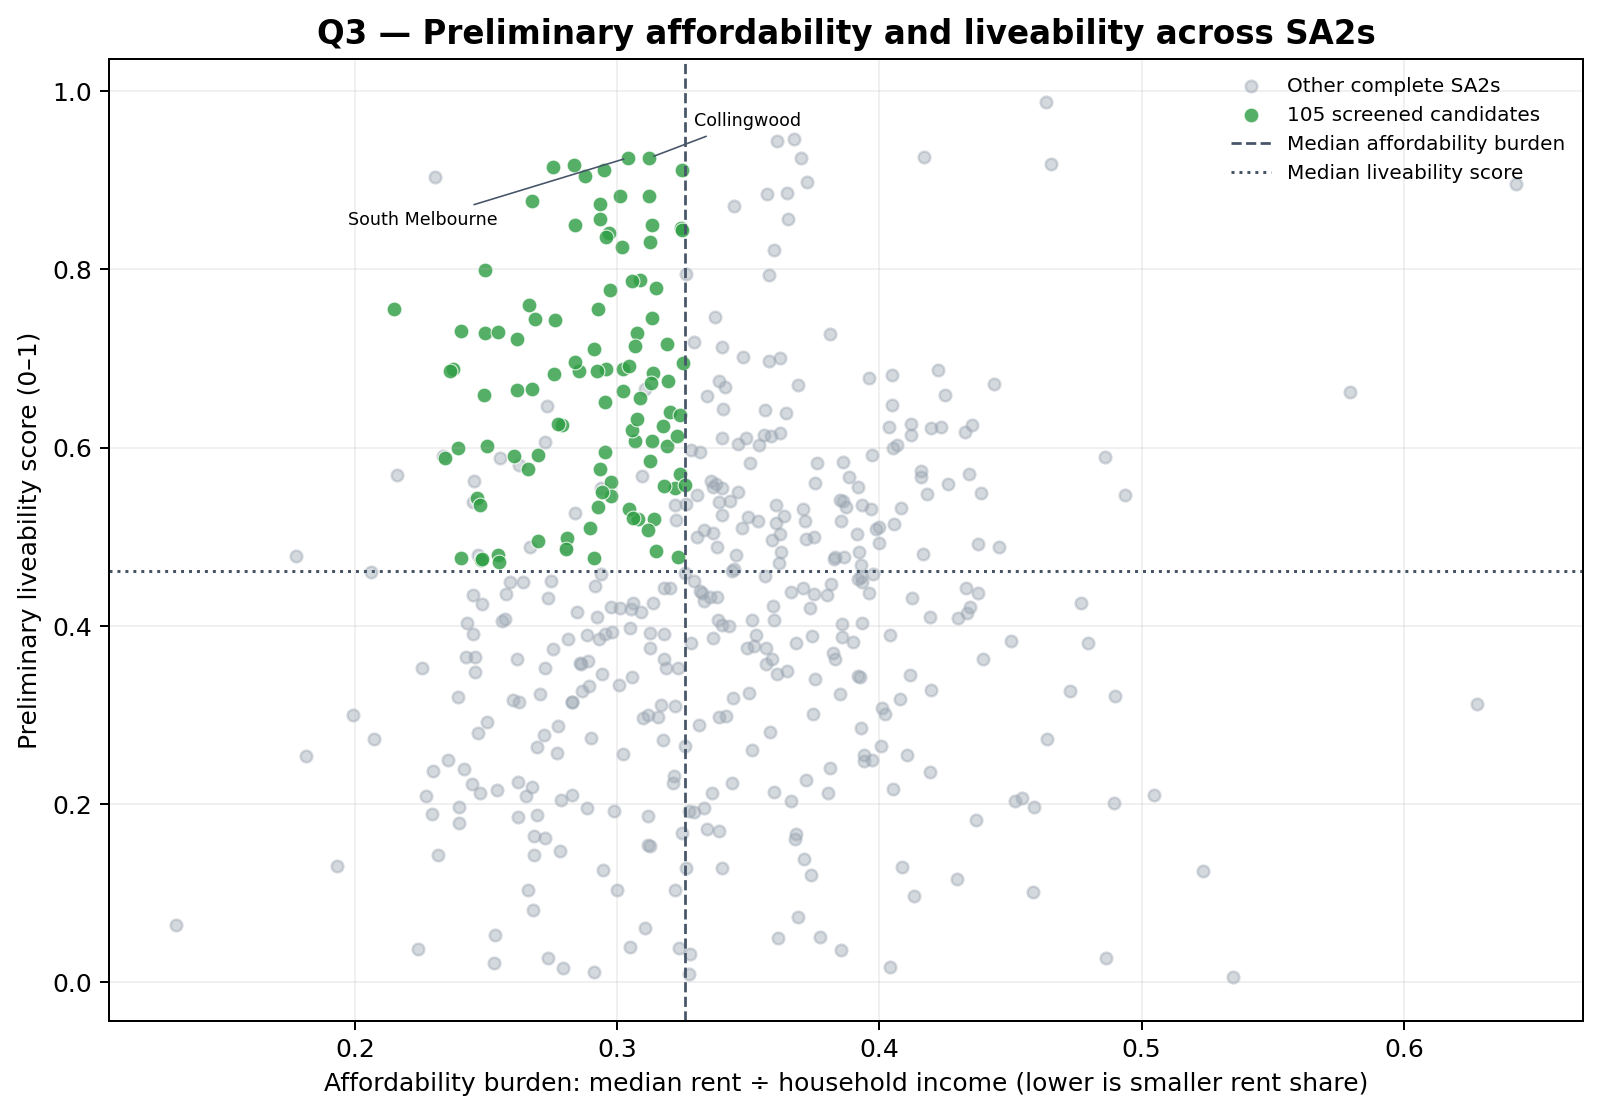

**Answer to Q3.** Affordability burden is current SA2 median weekly asking rent divided by 2021 Census median household weekly income; lower values mean rent is a smaller share of income. Preliminary liveability averages five equally weighted, percentile-scaled dimensions: nearest train, nearest school, and nearby park, shopping and entertainment provision. The Victoria-median thresholds first identified 124 SA2s; the existing minimum of 10 listings and special-purpose exclusion leave 105 illustrative candidates. This is a transparent comparison, not a complete housing-affordability measure or definitive liveability index. It omits factors such as housing quality, safety, household preferences and many individual circumstances; the dimensions and equal weights are provisional. The analysis unit is SA2, which should not automatically be described as a suburb. These current candidates are separate from Q2's future-rent-growth scenarios and are not a direct measure of demand.

**Weight sensitivity (baseline median cutoffs and all existing filters held fixed):**

,weight_scheme,candidate_count_after_existing_filters,candidate_overlap_with_baseline,candidate_jaccard_with_baseline,top10_overlap_with_baseline,spearman_score_correlation_with_baseline
0,equal_weight_baseline,105,105,1.000,10,1.000
1,transport_heavy,105,99,0.892,7,0.973
2,amenity_heavy,108,104,0.954,7,0.974


In [6]:
q3_display = result['q3_top10'][['sa2_name','listing_count','current_median_weekly_rent','median_household_weekly_income','affordability_burden','preliminary_liveability_score']].rename(columns={'sa2_name':'SA2','listing_count':'Listing count','current_median_weekly_rent':'Rent (AUD/week)','median_household_weekly_income':'Household income (AUD/week)','affordability_burden':'Affordability burden','preliminary_liveability_score':'Liveability score (0–1)'})
display(q3_display.round(3))
display(Image(filename=str(result['figure_paths']['q3'])))
display(Markdown('**Answer to Q3.** ' + result['q3_answer']))
q3_sensitivity = pd.read_csv(ROOT / 'data/processed/sprint6/q3_weight_sensitivity/q3_weight_sensitivity_summary.csv')
display(Markdown('**Weight sensitivity (baseline median cutoffs and all existing filters held fixed):**'))
display(q3_sensitivity[['weight_scheme','candidate_count_after_existing_filters','candidate_overlap_with_baseline','candidate_jaccard_with_baseline','top10_overlap_with_baseline','spearman_score_correlation_with_baseline']].round(3))

## 9. Integrated recommendations

The questions produce complementary evidence rather than a single league table: Q1 describes predictive associations in listing/SA2 data; Q2 gives uncertain rental-history growth scenarios; Q3 screens current affordability and local accessibility. The saved Q2–Q3 geography audit contains 54 one-to-one, 65 one-to-many and 26 ambiguous matches (zero unmatched). Because some rental-history groups map to several SA2s and SA2 is not equivalent to a suburb, a combined “best place” claim is not justified. The saved final integration reports zero confirmed balanced candidates under its one-to-one mapping condition; this does **not** prove that no such area exists. Keep growth monitoring, rent benchmarking and affordability/access comparisons as separate, qualified use cases.

In [7]:
display(result['geography_summary'])
q2_q1_q3_recommendations = result['final_recommendations'].loc[
    result['final_recommendations']['relevant_question'].isin(['Q1', 'Q3', 'Q2 + Q3'])
]
display(q2_q1_q3_recommendations)
display(Markdown('**Confirmed combined candidates under the saved rule:** {}. Interpretation: {}'.format(result['balanced_candidate_count'], result['takeaways']['balanced_candidate_qualification'])))
q2_examples = q2_5y_forecast.sort_values('predicted_growth_pct', ascending=False).head(3)
q2_text = '; '.join('{} ({:+.1f}% modelled; native rental-history market)'.format(row.market_id, row.predicted_growth_pct) for row in q2_examples.itertuples(index=False))
q3_examples = result['q3_top10'].head(3)
q3_text = '; '.join('{} (burden {:.3f}; liveability {:.3f})'.format(row.sa2_name, row.affordability_burden, row.preliminary_liveability_score) for row in q3_examples.itertuples(index=False))
display(Markdown('**Examples from separate results, not a combined shortlist.** Q2 registered five-year native-market examples: {}. Q3 SA2s passing the unchanged existing screen: {}. These Q3 examples are not asserted to match Q2 markets.'.format(q2_text, q3_text)))

,mapping_class,groups
0,one-to-one,54
1,one-to-many,65
2,ambiguous,26
3,unmatched,0


,market_or_sa2,relevant_question,scenario_or_screening_evidence,geography_confidence,recommendation_category,important_limitation
0,SA2-level current-rent benchmarking,Q1,Full feature set RMSE AUD 114.64/week vs prope...,SA2 aggregate predictive comparison; one saved...,Contextual price benchmarking,Not a causal model or a precise property-speci...
2,105 filtered SA2 candidates,Q3,Existing rent/income and provisional liveabili...,SA2 analysis unit; candidate-level screening.,Affordability/access comparison,The score is provisional and omits many househ...
3,No confirmed Q2–Q3 balanced candidate,Q2 + Q3,The saved final integration found zero candida...,"145-group mapping audit: 54 one-to-one, 65 one...",Keep objectives separate,This does not prove that no suitable area exis...


**Confirmed combined candidates under the saved rule:** 0. Interpretation: No market was confirmed under the chosen criteria and one-to-one geography condition; this is not evidence that no such area exists anywhere in Victoria.

**Examples from separate results, not a combined shortlist.** Q2 registered five-year native-market examples: Hamilton (+29.2% modelled; native rental-history market); Ballarat (+27.1% modelled; native rental-history market); Horsham (+26.0% modelled; native rental-history market). Q3 SA2s passing the unchanged existing screen: South Melbourne (burden 0.304; liveability 0.925); Collingwood (burden 0.312; liveability 0.925); Prahran - Windsor (burden 0.284; liveability 0.917). These Q3 examples are not asserted to match Q2 markets.

## 10. Business implications

The demonstrated prototype supports area-level asking-rent benchmarking, monitoring modelled rental-growth scenarios, and comparing rent/income with access to local amenities. These are decision-support views—not property valuations, investment guarantees, or a live-market product.

We can identify characteristics associated with higher rental prices, but we cannot directly infer rental demand or identify the most sought-after areas solely from these associations. The data do not provide aligned vacancy rates, applications per listing, enquiries, or days on market. Homes Victoria new-lease counts are a market-activity proxy, not direct demand.

A deployable service would need permissioned and regularly refreshed listing data, automated quality checks, updated geography crosswalks, model monitoring, stronger spatial/temporal validation, and a user-facing dashboard or API. Demand-specific data would be needed before making direct demand claims.

## 11. Limitations and assumptions

- The 3Y and 5Y historical growth backtests use overlapping moving-annual targets and annual origins; errors are descriptive, not independent trials or confidence intervals. The later two 3Y origins show substantial common-growth underprediction. Neither registered target has a mature outcome.
- The Q2 forecasts are for 145 native rental-history markets, not SA2s, suburbs, properties, or independently modelled mapped groups. Mapping proxies and sensitivity tests do not validate forecast accuracy.
- The 2025 Q3 archive is revised and its historical first-known publication vintages are incomplete. The resource's recorded 2026-02-20 release date does not prove when every value first became available. The registered forecasts were issued on 2026-10-16 using a 2025-09-30 information cutoff.
- Q1 uses one saved holdout plus random five-fold CV; neighbouring SA2s may be spatially dependent, so random CV does not prove transfer to new geographies. All results are predictive associations, not causal effects.
- Q3 uses current asking rents and 2021 Census income, five provisional equally weighted dimensions, and a minimum listing threshold. It omits many household circumstances and is not a definitive affordability or liveability index.
- We can identify characteristics associated with higher rental prices, but we cannot directly infer rental demand or identify the most sought-after areas solely from these associations. Vacancy, applications, enquiries and days-on-market are not observed; new leases are an activity proxy only.

**Offline reproduction.** From the repository root, execute this notebook with the course Python environment. The newly integrated Q2 forecast tables depend only on `data/processed/sprint6/q2_registered_research/` (two frozen CSVs and their provenance JSON), not on a private Codex research directory. The rest of the notebook still requires the existing project-local Sprint 6 cache or the authorised upstream processed-data bundle described in the README. No API call, ORS request, scraping, or download is made by this notebook. The restricted Domain source snapshot must remain local/authorised.

## 12. Final answers to Q1, Q2 and Q3

**Q1 - Current asking rent:** the broader feature set improved the saved holdout over property-only features, with IRSAD the strongest saved permutation-importance feature. The five-fold check is consistent with added socioeconomic and accessibility/amenity information, subject to spatial dependence.

**Q2 - Rental growth:** Ridge21 is the registered three-year research candidate and Ridge18 the registered five-year research candidate for 145 native Homes Victoria markets. Their 2028 Q3 and 2030 Q3 Top-10 predictions are shown above. Original Damped Holt outputs are retained unchanged as the earlier production/baseline scenario. Historical and mapping checks are not prospective accuracy; source-vintage and common-growth limitations remain material.

**Q3 - Affordability/liveability:** 105 SA2s pass the existing baseline screen after unchanged filters. South Melbourne, Collingwood and Prahran - Windsor are illustrative Q3 examples. Zero confirmed balanced Q2/Q3 matches reflects current filters and geography alignment; it does not show that no suitable area exists.

## 13. Reproducibility and Data References

- **Rental listings:** teacher-provided Domain Victoria snapshot (course-use restrictions and local provenance are recorded in `data/external/README.md`); public [Australian Rental Market Data 2026](https://www.kaggle.com/datasets/kanchana1990/australian-rental-market-data-2026). These are saved snapshots; parser code is not evidence of a live group scrape.
- **Historical rents:** [Homes Victoria Rental Report](https://www.dffh.vic.gov.au/publications/rental-report) and [Past Rental Reports](https://www.dffh.vic.gov.au/publications/past-rental-reports); the local 2023-2025 extracts and source-vintage treatment are documented in `data/external/README.md`.
- **Geography and socioeconomic context:** [ABS ASGS Edition 3 boundary files](https://www.abs.gov.au/statistics/standards/australian-statistical-geography-standard-asgs/edition-3-july-2021-june-2026/access-and-downloads/digital-boundary-files); 2021 Census income, SEIFA 2021 IRSAD and VIF2023 projections use the local files/provenance described in `data/external/README.md`.
- **Accessibility and amenities:** [Victorian School Locations 2025](https://discover.data.vic.gov.au/dataset/school-locations-2025), [Transport Victoria public-transport lines and stops](https://opendata.transport.vic.gov.au/dataset/public-transport-lines-and-stops), and statewide Vicmap [FOI centroid](https://discover.data.vic.gov.au/dataset/vicmap-features-features-of-interest-index-foi-centroid), [FOI polygon](https://discover.data.vic.gov.au/dataset/vicmap-features-features-of-interest-foi-polygon) and [Parks and Conservation Reserves](https://discover.data.vic.gov.au/dataset/parks-and-conservation-reserves-parkres). Saved routing-result provenance and coverage QA are in `data/processed/sprint3/audit.json`; this notebook reuses those results.

The presentation cache makes notebook display reproducible, not the entire upstream analysis. Rebuilding the summary or validation diagnostics requires the generated files under `data/processed/sprint3/`, `data/processed/sprint4/` and `data/processed/sprint5/`; most remain Git-ignored and must be restored from an authorised local bundle or regenerated in order. Existing saved route results are reused. Only an optional, deliberate route-generation workflow can create new ORS requests, and it requires a local `ORS_API_KEY`.

Dataset scope, licences, local file provenance, transformations and limitations are recorded in `data/external/README.md`, `docs/SPRINT3_ACCESSIBILITY.md` and `raw_data/shopping/SOURCE_MANIFEST.md`. Sources include [Homes Victoria Rental Reports](https://www.dffh.vic.gov.au/publications/rental-report), [ABS ASGS 2021 boundaries](https://www.abs.gov.au/statistics/standards/australian-statistical-geography-standard-asgs/edition-3-july-2021-june-2026/access-and-downloads/digital-boundary-files), [Transport Victoria public-transport data](https://opendata.transport.vic.gov.au/dataset/public-transport-lines-and-stops), and statewide [Vicmap FOI centroids](https://discover.data.vic.gov.au/dataset/vicmap-features-features-of-interest-index-foi-centroid) and [FOI polygons](https://discover.data.vic.gov.au/dataset/vicmap-features-features-of-interest-foi-polygon).

In [8]:
q2_q1_property_rmse = float(result['q1_summary'].loc[
    result['q1_summary']['feature_set'].eq('internal_property'), 'rmse_aud_week'
].iloc[0])
q2_q1_full_rmse = float(result['q1_summary'].loc[
    result['q1_summary']['feature_set'].eq('internal_socioeconomic_transport_amenities'), 'rmse_aud_week'
].iloc[0])
q2_q3_top3 = result['q3_top10']['sa2_name'].head(3).tolist()
q2_legacy_count = int(q2_legacy_forecasts['rank_5y'].notna().sum())
q2_registry_check_map = {check['Check']: check['Result'] for check in q2_registry_checks}
q2_checks = [
    {'Check': '3Y registered issue ID', 'Result': q2_registry_check_map['3y: frozen Stage 7 issue id']},
    {'Check': '5Y registered issue ID', 'Result': q2_registry_check_map['5y: frozen Stage 7 issue id']},
    {'Check': '145 unique native markets in both forecasts', 'Result': q2_registry_check_map['3y: 145 unique native markets'] and q2_registry_check_map['5y: 145 unique native markets']},
    {'Check': '12Q / 20Q target dates', 'Result': q2_registry_check_map['3y: candidate, horizon and target match frozen identity'] and q2_registry_check_map['5y: candidate, horizon and target match frozen identity']},
    {'Check': 'Growth reconstructed from endpoint rents', 'Result': q2_registry_check_map['3y: endpoint rent reconstructs growth'] and q2_registry_check_map['5y: endpoint rent reconstructs growth']},
    {'Check': 'Top-10 vectors match frozen issue records', 'Result': q2_registry_check_map['3y: Top-10 markets and values match provenance'] and q2_registry_check_map['5y: Top-10 markets and values match provenance']},
    {'Check': 'Q1 saved RMSE values reconcile', 'Result': abs(q2_q1_property_rmse - 131.819703) < 1e-6 and abs(q2_q1_full_rmse - 114.639410) < 1e-6},
    {'Check': 'Q3 top-three output is preserved', 'Result': q2_q3_top3 == ['South Melbourne', 'Collingwood', 'Prahran - Windsor']},
    {'Check': 'Earlier Damped Holt 5Y baseline remains present', 'Result': q2_legacy_count == 144 and len(q2_legacy_top10) == 10},
]
q2_validation_table = pd.DataFrame(q2_checks)
display(q2_validation_table)
assert q2_validation_table['Result'].all()
print('All integration checks passed; no API, ORS request, scraping, or download was used.')

,Check,Result
0,3Y registered issue ID,True
1,5Y registered issue ID,True
2,145 unique native markets in both forecasts,True
3,12Q / 20Q target dates,True
4,Growth reconstructed from endpoint rents,True
5,Top-10 vectors match frozen issue records,True
6,Q1 saved RMSE values reconcile,True
7,Q3 top-three output is preserved,True
8,Earlier Damped Holt 5Y baseline remains present,True


All integration checks passed; no API, ORS request, scraping, or download was used.
